# How Toxic Is X (Twitter)? Analysis

In this notebook we take the tweets we collected with `collect_x.py`, clean them, score them with three methods, and answer our three questions:

1. Which topics are the most toxic, and does that match our group's guess?
2. What kind of toxicity is most common in each topic?
3. What does a simple bad-word list miss compared with AI models?

The scoring step is slow, so we save the scores to `data/scored.csv` and reuse them next time.

> This notebook shows tweet text in its outputs. Before committing, clear them with
> `jupyter nbconvert --clear-output --inplace toxicity_analysis.ipynb`

## 0. Setup

In [1]:
import html
import json
import math
import re
import time
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr
from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support

DATA = Path("data")
RAW = DATA / "raw" / "combined.csv"
CLEAN = DATA / "clean.csv"
SCORED = DATA / "scored.csv"
SCORE_INFO = DATA / "scored_info.json"
LABELS = DATA / "labels"
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
BADWORDS = Path("resources/ldnoobw_en.txt")

THRESHOLD = 0.5
SEED = 42
rng = np.random.default_rng(SEED)

TOPIC_ORDER = ["us_politics", "kpop", "movies", "tech", "pets", "food"]
TOPIC_NAME = {"us_politics": "US Politics", "kpop": "K-pop", "movies": "Movies",
              "tech": "Tech", "pets": "Pets", "food": "Food"}
GUESS = {"us_politics": "High", "kpop": "High", "movies": "Mid",
         "tech": "Mid", "pets": "Low", "food": "Low"}
LEVEL_NUM = {"High": 3, "Mid": 2, "Low": 1}
SEED_TAGS = ["uspolitics", "republicans", "democrats", "bts", "blackpink", "kpop",
             "movies", "film", "netflix", "ai", "tech", "iphone",
             "pets", "catlovers", "doglovers", "recipe", "cooking", "foodie"]

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data

We start from `combined.csv`. It has all posts and replies from the 6 topics in one table, and the `type` column tells them apart.

In [2]:
raw = pd.read_csv(RAW, dtype={"tweet_id": str, "parent_id": str})
raw["text"] = raw["text"].fillna("")
raw["parent_text"] = raw["parent_text"].fillna("")
print(f"{len(raw):,} tweets")
raw[["topic", "hashtag", "type", "text"]].head()

2,829 tweets


,topic,hashtag,type,text
0,food,cooking,post,I'm up to something 😉⭐\n#Cooking #holidayseason 🧑🏽‍🍳 https://t.co/AcQv4JA5jD
1,food,cooking,post,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTixtt via @You...
2,food,cooking,post,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTj5j1 via @You...
3,food,cooking,post,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥
4,food,cooking,post,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...


In [3]:
raw.pivot_table(index="topic", columns="type", values="tweet_id", aggfunc="count").reindex(TOPIC_ORDER)

type,post,reply
topic,,
us_politics,308,179
kpop,313,139
movies,308,226
tech,313,205
pets,304,68
food,300,166


## 2. Clean

Many posts are ads or shop links, not people talking. Replies also start with @names that are not part of the message. Our plan:

1. Remove **promo** tweets: a link **and** 3 or more hashtags. We check this before cleaning, while the links are still there.
2. Clean the text: decode `&amp;`, remove the @names at the start of replies, remove links.
3. Remove the same text repeated in one topic (copy-paste fan campaigns, bots).
4. Remove texts shorter than 3 words ("lol", "W"). They are too short to judge.

We keep two versions of the text. `text_clean` has no @names or links, and we use it for the word list and LDA. `text_model` replaces them with `@user` and `http`, because that's how Twitter-RoBERTa was trained.

In [4]:
URL = re.compile(r"https?://\S+")
LEAD_MENTIONS = re.compile(r"^(?:\s*@\w+)+")
MENTION = re.compile(r"@\w+")


def clean_text(t):
    t = html.unescape(t)
    t = LEAD_MENTIONS.sub("", t)
    t = URL.sub("", t)
    t = MENTION.sub("", t)
    return " ".join(t.split())


def model_text(t):
    t = html.unescape(t)
    t = LEAD_MENTIONS.sub("", t)
    t = URL.sub("http", t)
    t = MENTION.sub("@user", t)
    return " ".join(t.split())


df = raw.copy()
df["is_promo"] = df["text"].str.contains(URL) & (df["text"].str.count(r"#\w+") >= 3)
df["text_clean"] = df["text"].map(clean_text)
df["text_model"] = df["text"].map(model_text)
df["parent_clean"] = df["parent_text"].map(clean_text)
df[["type", "is_promo", "text", "text_clean"]].head()

,type,is_promo,text,text_clean
0,post,False,I'm up to something 😉⭐\n#Cooking #holidayseason 🧑🏽‍🍳 https://t.co/AcQv4JA5jD,I'm up to something 😉⭐ #Cooking #holidayseason 🧑🏽‍🍳
1,post,True,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTixtt via @You...,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food via So Good.
2,post,True,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTj5j1 via @You...,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food via
3,post,False,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥
4,post,False,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...


Now we apply the four steps and count how many tweets are left after each one.

In [5]:
steps = {"1. collected": df.groupby(["topic", "type"]).size()}

df = df[~df["is_promo"]]
steps["2. no promo"] = df.groupby(["topic", "type"]).size()

df = (df.assign(_key=df["text_clean"].str.lower())
        .drop_duplicates(["topic", "type", "_key"]).drop(columns="_key"))
steps["3. no duplicates"] = df.groupby(["topic", "type"]).size()

df = df[df["text_clean"].str.split().str.len() >= 3]
steps["4. 3+ words"] = df.groupby(["topic", "type"]).size()

clean = df.reset_index(drop=True)
assert clean["tweet_id"].is_unique
clean[["topic", "level", "hashtag", "type", "tweet_id", "parent_id", "created_at",
       "text_clean", "text_model", "parent_clean"]].to_csv(CLEAN, index=False, encoding="utf-8")

print(f"Kept {len(clean):,} of {len(raw):,} tweets")
(pd.DataFrame(steps).unstack("type").fillna(0).astype(int)
   .reindex(TOPIC_ORDER).rename(index=TOPIC_NAME))

Kept 1,594 of 2,829 tweets


1. collected       2. no promo       3. no duplicates        \
type                post reply        post reply             post reply   
topic                                                                     
US Politics          308   179         194   179              190   179   
K-pop                313   139         117   137              116   123   
Movies               308   226         135   226              133   209   
Tech                 313   205         144   204              144   192   
Pets                 304    68          92    68               84    66   
Food                 300   166         117   166              113   162   

            4. 3+ words        
type               post reply  
topic                          
US Politics         189   173  
K-pop               115   102  
Movies              133   180  
Tech                144   169  
Pets                 83    53  
Food                113   140

The promo filter removes most **posts** in pets, food and K-pop, which were mostly ads. Replies are almost untouched, because people write them, not shops.

## 3. Score

We score every tweet with three methods:

| Method | Idea | Output |
|---|---|---|
| Bad-word list | Is any word from the LDNOOBW list in the tweet? No learning | number of bad words |
| Detoxify (unbiased) | AI model trained on online comments | 7 scores from 0 to 1 (toxicity, insult, threat, ...) |
| Twitter-RoBERTa | AI model trained on tweets | 1 score from 0 to 1 (offensive) |

A tweet counts as toxic when the score is 0.5 or more (or, for the list, when it has at least one bad word).

### 3.1 Bad-word list

We match whole words, not parts of words. So "class" doesn't match "ass".

In [6]:
from nltk.tokenize import TweetTokenizer

words = [w.strip().lower() for w in BADWORDS.read_text(encoding="utf-8").splitlines() if w.strip()]
BW_SINGLE = {w for w in words if " " not in w}
BW_PHRASES = sorted((w for w in words if " " in w), key=len, reverse=True)
BW_PHRASE_RE = re.compile(r"\b(" + "|".join(map(re.escape, BW_PHRASES)) + r")\b")
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)


def badword_hits(text):
    t = text.lower().replace("#", "")
    hits = [w for w in tokenizer.tokenize(t) if w in BW_SINGLE]
    hits += BW_PHRASE_RE.findall(t)
    return hits


print(f"{len(BW_SINGLE)} words and {len(BW_PHRASES)} phrases in the list")
for s in ["This game is fucking awesome!", "You are so stupid, uninstall the game", "first class ticket"]:
    print(f"{s!r} -> {badword_hits(s)}")

279 words and 124 phrases in the list
'This game is fucking awesome!' -> ['fucking']
'You are so stupid, uninstall the game' -> []
'first class ticket' -> []


### 3.2 AI models

We load the Detoxify `unbiased` model weights directly with `transformers` (the `detoxify` package doesn't install cleanly with our versions). Detoxify gives several labels at once, so we use **sigmoid**. RoBERTa picks one of two classes, so we use **softmax**.

If `scored.csv` already has exactly the same tweets as `clean.csv`, we just load it. If the cleaning changed, we score again.

In [7]:
DETOX_ID = "unitary/unbiased-toxic-roberta"
ROBERTA_ID = "cardiffnlp/twitter-roberta-base-offensive"
DETOX_COLS = ["toxicity", "severe_toxicity", "obscene", "identity_attack",
              "insult", "threat", "sexual_explicit"]


def run_model(model_id, texts, activation, batch_size=32):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id).eval()
    labels = [model.config.id2label[i] for i in range(model.config.num_labels)]
    out, t0 = [], time.time()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=128, return_tensors="pt")
            logits = model(**enc).logits
            probs = torch.sigmoid(logits) if activation == "sigmoid" else torch.softmax(logits, -1)
            out.append(probs.numpy())
    print(f"{model_id}: {len(texts):,} tweets in {time.time() - t0:.0f}s")
    return pd.DataFrame(np.vstack(out), columns=labels)


def score_all(clean):
    s = clean.copy()
    s["bw_words"] = s["text_clean"].map(lambda t: "|".join(badword_hits(t)))
    s["bw_count"] = s["bw_words"].map(lambda x: len(x.split("|")) if x else 0)
    texts = s["text_model"].tolist()
    detox = run_model(DETOX_ID, texts, "sigmoid")[DETOX_COLS]   # skip the identity-group labels
    s[[f"detox_{c}" for c in DETOX_COLS]] = detox.to_numpy()
    s["roberta_offensive"] = run_model(ROBERTA_ID, texts, "softmax")["offensive"].to_numpy()
    return s


clean = pd.read_csv(CLEAN, dtype={"tweet_id": str, "parent_id": str}).fillna({"parent_clean": "", "parent_id": ""})
scored = None
if SCORED.exists():
    old = pd.read_csv(SCORED, dtype={"tweet_id": str, "parent_id": str})
    if len(old) == len(clean) and set(old["tweet_id"]) == set(clean["tweet_id"]):
        scored = old
        print(f"Loaded saved scores ({len(scored):,} tweets). Delete {SCORED} to score again.")

if scored is None:
    scored = score_all(clean)
    scored.to_csv(SCORED, index=False, encoding="utf-8")
    import torch, transformers
    SCORE_INFO.write_text(json.dumps({
        "date": datetime.now().isoformat(timespec="seconds"),
        "detoxify_model": DETOX_ID, "roberta_model": ROBERTA_ID,
        "transformers": transformers.__version__, "torch": torch.__version__,
        "n_tweets": len(scored)}, indent=2))

scored = scored.fillna({"bw_words": "", "parent_id": "", "parent_clean": ""})
scored["detox_toxic"] = (scored["detox_toxicity"] >= THRESHOLD).astype(int)
scored["roberta_toxic"] = (scored["roberta_offensive"] >= THRESHOLD).astype(int)
scored["bw_toxic"] = (scored["bw_count"] > 0).astype(int)
scored[["topic", "type", "bw_count", "detox_toxicity", "detox_insult", "roberta_offensive"]].head()

Loaded saved scores (1,594 tweets). Delete data\scored.csv to score again.


,topic,type,bw_count,detox_toxicity,detox_insult,roberta_offensive
0,food,post,0,0.000388,0.000122,0.043522
1,food,post,0,0.000597,0.000179,0.035957
2,food,post,0,0.073444,0.006012,0.555168
3,food,post,0,0.000399,0.000122,0.109914
4,food,post,0,0.000412,0.000131,0.038549


Quick check that the models aren't upside down: a clear insult should score high, and a kind message low.

In [8]:
for name, needle in [("insult", "YOU ARE THE DUMBEST"), ("kind", "RIP SWEET ANGEL")]:
    r = scored[scored["text_clean"].str.contains(needle, case=False, regex=False)].iloc[0]
    print(f"{name:6}: Detoxify {r['detox_toxicity']:.2f}, RoBERTa {r['roberta_offensive']:.2f}, bad words {r['bw_count']}")

insult: Detoxify 1.00, RoBERTa 0.93, bad words 3
kind  : Detoxify 0.00, RoBERTa 0.07, bad words 0


### 3.3 First look: results of each method

Before the detailed questions, here are the three methods side by side: the % of toxic tweets per topic, with the number of toxic tweets and all tweets in brackets. Small groups (like Pets replies, 53 tweets) can change a lot with one tweet.

In [9]:
methods = {"Detoxify": "detox_toxic", "RoBERTa": "roberta_toxic", "Word list": "bw_toxic"}


def method_table(kind):
    g = scored[scored["type"] == kind]
    k = g.groupby("topic")[list(methods.values())].sum().reindex(TOPIC_ORDER)
    n = g.groupby("topic").size().reindex(TOPIC_ORDER)
    return pd.DataFrame({name: [f"{100 * k.loc[t, col] / n[t]:.1f}% ({k.loc[t, col]}/{n[t]})" for t in TOPIC_ORDER]
                         for name, col in methods.items()},
                        index=pd.Index([TOPIC_NAME[t] for t in TOPIC_ORDER], name="topic"))


print("Toxic tweets in total: " + ", ".join(f"{name} {scored[col].sum()}" for name, col in methods.items())
      + f" (of {len(scored):,})")
print()
print("Replies: % toxic (toxic/all)")
display(method_table("reply"))
print("Posts: % toxic (toxic/all)")
display(method_table("post"))

Toxic tweets in total: Detoxify 122, RoBERTa 160, Word list 47 (of 1,594)

Replies: % toxic (toxic/all)


,Detoxify,RoBERTa,Word list
topic,,,
US Politics,21.4% (37/173),32.4% (56/173),11.0% (19/173)
K-pop,11.8% (12/102),11.8% (12/102),1.0% (1/102)
Movies,3.3% (6/180),5.0% (9/180),0.6% (1/180)
Tech,0.6% (1/169),3.0% (5/169),0.0% (0/169)
Pets,5.7% (3/53),7.5% (4/53),1.9% (1/53)
Food,2.9% (4/140),4.3% (6/140),1.4% (2/140)


Posts: % toxic (toxic/all)


,Detoxify,RoBERTa,Word list
topic,,,
US Politics,20.1% (38/189),24.3% (46/189),5.8% (11/189)
K-pop,5.2% (6/115),5.2% (6/115),3.5% (4/115)
Movies,5.3% (7/133),3.8% (5/133),1.5% (2/133)
Tech,2.1% (3/144),3.5% (5/144),2.1% (3/144)
Pets,2.4% (2/83),3.6% (3/83),2.4% (2/83)
Food,2.7% (3/113),2.7% (3/113),0.9% (1/113)


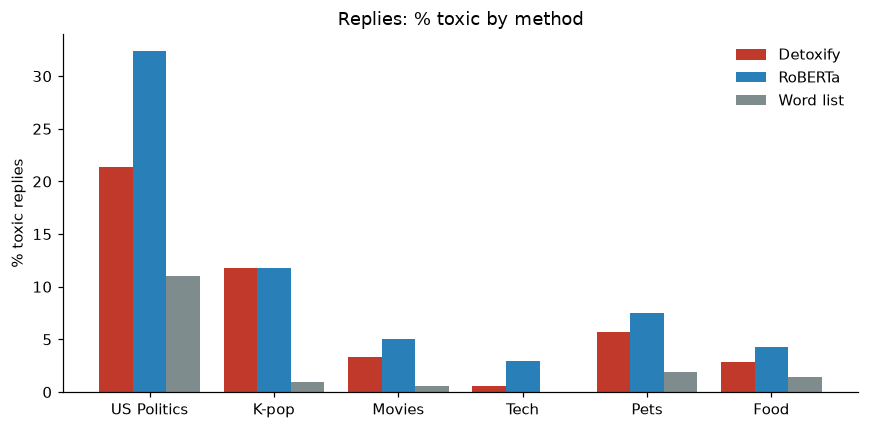

In [10]:
reply_pct = (scored[scored["type"] == "reply"].groupby("topic")[list(methods.values())].mean()
             .reindex(TOPIC_ORDER) * 100)
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, color) in enumerate([("Detoxify", "#c0392b"), ("RoBERTa", "#2980b9"), ("Word list", "#7f8c8d")]):
    ax.bar(np.arange(6) + (i - 1) * 0.27, reply_pct[methods[name]], 0.27, label=name, color=color)
ax.set_xticks(np.arange(6), [TOPIC_NAME[t] for t in TOPIC_ORDER])
ax.set_ylabel("% toxic replies")
ax.set_title("Replies: % toxic by method")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig2_methods_replies.png", bbox_inches="tight")
plt.show()

**What we see**

- **All three methods put US Politics first**, for replies and for posts. For replies: Detoxify 21.4%, RoBERTa 32.4%, word list 11.0%.
- **Detoxify and RoBERTa give the same order for replies:** US Politics > K-pop > Pets > Movies > Food > Tech. RoBERTa flags more tweets overall (160 vs 122).
- **The word list finds almost nothing outside politics:** 0–2 replies per topic (0–1.9%). So its order for the other 5 topics depends on 1 or 2 tweets.
- **Posts are closer together.** Apart from US Politics (20–24% with the AI models), all topics are between 2% and 5%, so their order can change with one tweet.

## 4. Question 1: Which topics are the most toxic?

We look at the % of toxic tweets (Detoxify) per topic, for replies and posts separately. **Replies are our main result**, because that's where people talk to each other.

For each % we also compute a 95% confidence interval with a bootstrap. For replies, we resample whole threads, not single replies, because replies under the same post are not independent.

In [11]:
def boot_ci(g, col, cluster=None, n_boot=2000):
    if cluster is None:
        x = g[col].to_numpy(float)
        means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
    else:
        parts = [v[col].to_numpy(float) for _, v in g.groupby(cluster)]
        sums = np.array([p.sum() for p in parts])
        cnts = np.array([len(p) for p in parts])
        idx = rng.integers(0, len(parts), (n_boot, len(parts)))
        means = sums[idx].sum(1) / cnts[idx].sum(1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return 100 * lo, 100 * hi


rows = []
for (topic, kind), g in scored.groupby(["topic", "type"]):
    lo, hi = boot_ci(g, "detox_toxic", cluster="parent_id" if kind == "reply" else None)
    rows.append({"topic": topic, "type": kind, "n": len(g),
                 "detox_%": 100 * g["detox_toxic"].mean(), "ci_low": lo, "ci_high": hi,
                 "roberta_%": 100 * g["roberta_toxic"].mean(),
                 "badword_%": 100 * g["bw_toxic"].mean()})
obj1 = pd.DataFrame(rows)
obj1["topic"] = pd.Categorical(obj1["topic"], TOPIC_ORDER, ordered=True)
obj1 = obj1.sort_values(["type", "topic"]).reset_index(drop=True)
obj1[obj1["type"] == "reply"][["topic", "n", "detox_%", "ci_low", "ci_high"]].round(1)

,topic,n,detox_%,ci_low,ci_high
6,us_politics,173,21.4,15.7,27.4
7,kpop,102,11.8,2.6,22.0
8,movies,180,3.3,1.0,6.2
9,tech,169,0.6,0.0,1.8
10,pets,53,5.7,0.0,11.3
11,food,140,2.9,0.8,5.0


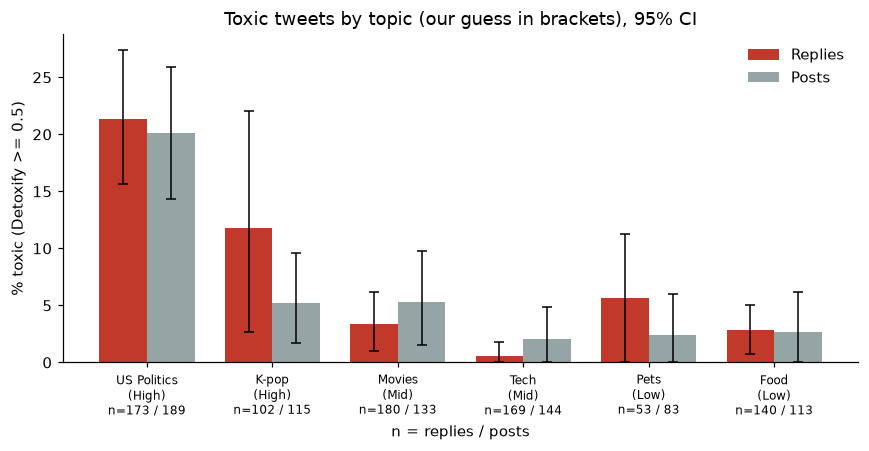

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(TOPIC_ORDER))
w = 0.38
n = obj1.pivot(index="topic", columns="type", values="n").reindex(TOPIC_ORDER)
for i, (kind, label, color) in enumerate([("reply", "Replies", "#c0392b"), ("post", "Posts", "#95a5a6")]):
    d = obj1[obj1["type"] == kind].set_index("topic").reindex(TOPIC_ORDER)
    err = [d["detox_%"] - d["ci_low"], d["ci_high"] - d["detox_%"]]
    ax.bar(x + (i - 0.5) * w, d["detox_%"], w, yerr=err, capsize=3, color=color,
           error_kw={"elinewidth": 1}, label=label)
ax.set_xticks(x, [f"{TOPIC_NAME[t]}\n({GUESS[t]})\nn={n.loc[t, 'reply']} / {n.loc[t, 'post']}"
                  for t in TOPIC_ORDER], fontsize=8)
ax.set_xlabel("n = replies / posts")
ax.set_ylabel("% toxic (Detoxify >= 0.5)")
ax.set_title("Toxic tweets by topic (our guess in brackets), 95% CI")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig1_toxic_by_topic.png", bbox_inches="tight")
plt.show()

### Are the differences real?

The chi-square test checks whether these differences could just be chance. A p-value below 0.05 means the topics really differ. (It assumes tweets are independent. Replies in one thread are not fully independent, so the reply p-value is only approximate.)

In [13]:
for kind in ["reply", "post"]:
    g = scored[scored["type"] == kind]
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(g["topic"], g["detox_toxic"]))
    print(f"{kind:5}: chi2 = {chi2:.1f}, p = {p:.2g}")

g = scored.groupby("type")["detox_toxic"].mean() * 100
print(f"\nAll topics together: replies {g['reply']:.1f}% toxic, posts {g['post']:.1f}% toxic")

reply: chi2 = 69.7, p = 1.2e-13
post : chi2 = 57.5, p = 4.1e-11

All topics together: replies 7.7% toxic, posts 7.6% toxic


### Does the threshold matter?

We used 0.5. Here we also try 0.3 and 0.7. If the order of the topics stays about the same, our result is stable.

In [14]:
rows = {}
for t in [0.3, 0.5, 0.7]:
    for kind in ["reply", "post"]:
        g = scored[scored["type"] == kind]
        rows[(kind, f">= {t}")] = (g["detox_toxicity"] >= t).groupby(g["topic"]).mean() * 100
pd.DataFrame(rows).reindex(TOPIC_ORDER).rename(index=TOPIC_NAME).round(1)

,reply,post,reply,post,reply,post
,>= 0.3,>= 0.3,>= 0.5,>= 0.5,>= 0.7,>= 0.7
topic,,,,,,
US Politics,24.3,23.3,21.4,20.1,18.5,18.0
K-pop,12.7,6.1,11.8,5.2,7.8,4.3
Movies,6.1,5.3,3.3,5.3,2.8,5.3
Tech,1.2,2.8,0.6,2.1,0.0,2.1
Pets,5.7,3.6,5.7,2.4,3.8,2.4
Food,3.6,2.7,2.9,2.7,1.4,1.8


### Our guess vs. the data

Our vote put **2 topics in each level**. We do the same with the data, for each method separately:

1. Take the % of toxic replies per topic (the table in 3.3).
2. Sort the 6 topics from most to least toxic.
3. Top 2 = **High**, middle 2 = **Mid**, bottom 2 = **Low**.

We don't use fixed cut-offs like "10% or more = High", because there is no standard number for that, and the three methods give very different %. So the levels are **relative**: High means "among the 2 most toxic of our 6 topics", the same way we voted.

Then we count how many topics match our guess. Spearman checks whether the topics come in the same order as our guess (1 = same order, 0 = no relation). With only 6 topics, take it as a rough guide.

In [15]:
def to_levels(pct):
    order = pct.sort_values(ascending=False, kind="stable").index   # most toxic first
    return pd.Series(["High"] * 2 + ["Mid"] * 2 + ["Low"] * 2, index=order)


def ranked(kind, col):
    pct = (scored[scored["type"] == kind].groupby("topic")[col].mean() * 100).reindex(TOPIC_ORDER)
    levels = to_levels(pct)
    order = levels.index
    table = pd.DataFrame({"topic": [TOPIC_NAME[t] for t in order],
                          "% toxic": pct[order].round(1).to_numpy(),
                          "data level": levels.to_numpy(),
                          "our guess": [GUESS[t] for t in order]},
                         index=pd.RangeIndex(1, 7, name="rank"))
    table["match"] = np.where(table["data level"] == table["our guess"], "yes", "no")
    return pct, table


summary_rows = []
for kind in ["reply", "post"]:
    for name, col in methods.items():
        pct, table = ranked(kind, col)
        rho = spearmanr([LEVEL_NUM[GUESS[t]] for t in TOPIC_ORDER], pct.to_numpy())[0]
        summary_rows.append({"method": name, "type": kind,
                             "match": f"{(table['match'] == 'yes').sum()}/6", "spearman": round(rho, 2)})
        if kind == "reply":
            print(f"{name}, replies")
            display(table)
pd.DataFrame(summary_rows)

Detoxify, replies


,topic,% toxic,data level,our guess,match
rank,,,,,
1,US Politics,21.4,High,High,yes
2,K-pop,11.8,High,High,yes
3,Pets,5.7,Mid,Low,no
4,Movies,3.3,Mid,Mid,yes
5,Food,2.9,Low,Low,yes
6,Tech,0.6,Low,Mid,no


RoBERTa, replies


,topic,% toxic,data level,our guess,match
rank,,,,,
1,US Politics,32.4,High,High,yes
2,K-pop,11.8,High,High,yes
3,Pets,7.5,Mid,Low,no
4,Movies,5.0,Mid,Mid,yes
5,Food,4.3,Low,Low,yes
6,Tech,3.0,Low,Mid,no


Word list, replies


,topic,% toxic,data level,our guess,match
rank,,,,,
1,US Politics,11.0,High,High,yes
2,Pets,1.9,High,Low,no
3,Food,1.4,Mid,Low,no
4,K-pop,1.0,Mid,High,no
5,Movies,0.6,Low,Mid,no
6,Tech,0.0,Low,Mid,no


,method,type,match,spearman
0,Detoxify,reply,4/6,0.60
1,RoBERTa,reply,4/6,0.60
2,Word list,reply,1/6,0.00
3,Detoxify,post,2/6,0.60
4,RoBERTa,post,4/6,0.84
5,Word list,post,4/6,0.72


**What this shows**

- **Detoxify 4/6 and RoBERTa 4/6 (replies).** Both get US Politics and K-pop (High), Movies (Mid) and Food (Low) right. Both miss the same 2 topics: Tech is less toxic than we guessed (Low, not Mid), and Pets is more toxic (Mid, not Low). Pets is only 3–4 toxic replies out of 53, so that miss is weak.
- **Some cuts are close.** With Detoxify, Movies (3.3%, 6 of 180) is Mid and Food (2.9%, 4 of 140) is Low.
- **Word list 1/6 (replies).** Only US Politics matches. Outside politics it finds 0–2 bad-word replies per topic, so Pets is "High" because of 1 reply. This ranking is not reliable.
- **Posts.** Detoxify gets only 2/6, mostly because of one tweet: Movies (5.3%, 7 of 133) is just above K-pop (5.2%, 6 of 115), so Movies takes the second High place. With one tweet less for Movies, it would be 4/6, like RoBERTa.

## 5. Question 2: What kind of toxicity?

For each toxic tweet, we take the type with the highest Detoxify score: obscene, insult, threat, identity attack or sexual. We skip `toxicity` and `severe_toxicity`, because they say *how* toxic, not *what kind*. Posts and replies are combined to get more tweets. Topics with a small n are not reliable.

In [16]:
TYPE_COLS = ["obscene", "insult", "threat", "identity_attack", "sexual_explicit"]
tox = scored[scored["detox_toxic"] == 1].copy()
tox["tox_type"] = [TYPE_COLS[i] for i in tox[[f"detox_{c}" for c in TYPE_COLS]].to_numpy().argmax(1)]
tox[["topic", "tox_type", "text_clean"]].head(3)

,topic,tox_type,text_clean
8,food,threat,ive decided to kill two characters in the final battle of my hunger games au so far #cooking
16,food,insult,One of the dumbest things we do as adults is grabbing or picking up something to see if it’s sti...
76,food,obscene,Damn these look so good! I’ll make these or have my son do it since he’s been the chef lately ☺️


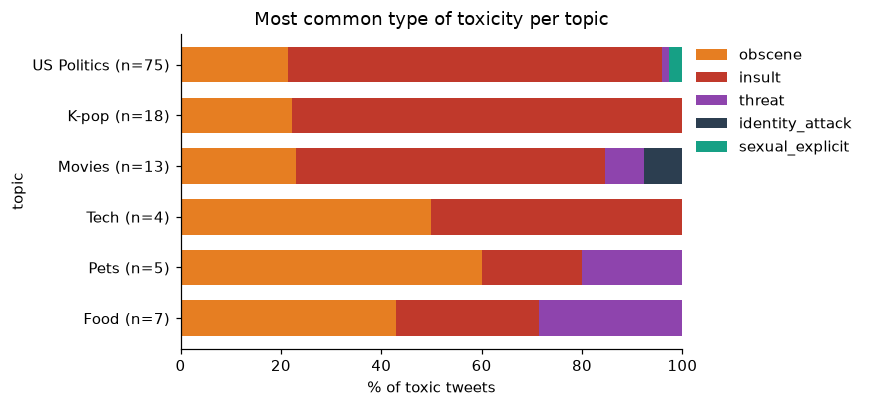

tox_type,obscene,insult,threat,identity_attack,sexual_explicit,n_toxic
topic,,,,,,
US Politics,21.0,75.0,1.0,0.0,3.0,75
K-pop,22.0,78.0,0.0,0.0,0.0,18
Movies,23.0,62.0,8.0,8.0,0.0,13
Tech,50.0,50.0,0.0,0.0,0.0,4
Pets,60.0,20.0,20.0,0.0,0.0,5
Food,43.0,29.0,29.0,0.0,0.0,7


In [17]:
types = pd.crosstab(tox["topic"], tox["tox_type"]).reindex(index=TOPIC_ORDER, columns=TYPE_COLS).fillna(0)
n_toxic = types.sum(axis=1).astype(int)
types_pct = types.div(n_toxic.replace(0, np.nan), axis=0) * 100

ax = types_pct.rename(index=TOPIC_NAME).plot(kind="barh", stacked=True, figsize=(8, 3.8), width=0.7,
                                             color=["#e67e22", "#c0392b", "#8e44ad", "#2c3e50", "#16a085"])
ax.set_yticklabels([f"{TOPIC_NAME[t]} (n={n_toxic[t]})" for t in TOPIC_ORDER])
ax.invert_yaxis()
ax.set_xlabel("% of toxic tweets")
ax.set_title("Most common type of toxicity per topic")
ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "fig3_toxicity_types.png", bbox_inches="tight")
plt.show()
types_pct.round(0).assign(n_toxic=n_toxic).rename(index=TOPIC_NAME)

## 6. Question 3: What does the bad-word list miss?

We don't have human labels yet, so first we compare the methods with each other. This shows *where* they disagree, not who is right. The hand labels (6.3) will tell us who is right.

Cohen's kappa is agreement after removing lucky agreement (0 = chance, 1 = perfect).

In [18]:
methods = {"Word list": "bw_toxic", "Detoxify": "detox_toxic", "RoBERTa": "roberta_toxic"}
rows = []
for a, b in [("Word list", "Detoxify"), ("Word list", "RoBERTa"), ("Detoxify", "RoBERTa")]:
    x, y = scored[methods[a]], scored[methods[b]]
    rows.append({"pair": f"{a} vs {b}", "% agree": round(100 * (x == y).mean(), 1),
                 "kappa": round(cohen_kappa_score(x, y), 2)})
pd.DataFrame(rows)

,pair,% agree,kappa
0,Word list vs Detoxify,94.3,0.44
1,Word list vs RoBERTa,92.4,0.39
2,Detoxify vs RoBERTa,95.1,0.70


### 6.1 Misses: the model says toxic, but there is no bad word

In [19]:
miss = scored[(scored["detox_toxic"] == 1) & (scored["bw_toxic"] == 0)]
print(f"{len(miss)} of {scored['detox_toxic'].sum()} toxic tweets have no word from the list")
ex = miss.sample(min(5, len(miss)), random_state=SEED)
ex.assign(type=[TYPE_COLS[i] for i in ex[[f"detox_{c}" for c in TYPE_COLS]].to_numpy().argmax(1)])[
    ["topic", "type", "detox_toxicity", "text_clean"]].round(2)

83 of 122 toxic tweets have no word from the list


,topic,type,detox_toxicity,text_clean
772,movies,insult,0.84,OMG THEY'RE BABIESSSS
8,food,threat,0.59,ive decided to kill two characters in the final battle of my hunger games au so far #cooking
581,movies,insult,0.99,That's the problem right there. Batman should have been his first or second project along with S...
779,movies,obscene,0.63,i freaking need the zoom meeting video neowwww
417,kpop,obscene,0.84,listener request unlocked 🔥 JENNIE — Damn Right (feat. Childish Gambino & Kali Uchis) from Ruby ...


### 6.2 False alarms: a bad word is there, but the model says not toxic

In [20]:
fa = scored[(scored["bw_toxic"] == 1) & (scored["detox_toxic"] == 0)]
print(f"{len(fa)} of {scored['bw_toxic'].sum()} word-list hits are not toxic for Detoxify")
print("Most common words:", Counter(w for ws in fa["bw_words"] for w in ws.split("|") if w).most_common(8))
fa.sample(min(5, len(fa)), random_state=SEED)[["topic", "bw_words", "detox_toxicity", "text_clean"]].round(2)

8 of 47 word-list hits are not toxic for Detoxify
Most common words: [('🖕', 2), ('rapist', 2), ('sexy', 1), ('butt', 1), ('bollocks', 1), ('raping', 1), ('wet dream', 1)]


,topic,bw_words,detox_toxicity,text_clean
363,kpop,🖕,0.00,It went from 🖕 to 🫰. “Thank you BTS.” #BTSeffect #BTS
1069,tech,bollocks,0.13,Every update someone cooks up some made up bollocks they’ve turned this on and you should turn i...
239,food,sexy,0.03,"Justin, you’re sexy"
1446,us_politics,wet dream,0.49,Crazy right? Almost like it's a globalist wet dream!
420,kpop,rapist|rapist,0.47,"They say god impregnated Mary at 12 years old, unconsented. That makes him a pedo/rapist. Jesus ..."


### 6.3 Hand-label sheet

To know which method is right, two of us label the same 250 tweets by hand.

- Only about 1 in 9 tweets is flagged by any method, so a random 250 would have very few toxic tweets. We take **half flagged and half not flagged**, spread over the topics.
- The sheet shows only the text (and the post it replies to). There's no topic and no score, so we aren't influenced.
- Each labeler fills `toxic` (1 or 0) and, if toxic, `type` (insult, obscene, threat, identity_attack, sexual). Then saves it as `label_sheet_A_filled.csv` or `label_sheet_B_filled.csv` in `data/labels/`.

In [21]:
LABELS.mkdir(parents=True, exist_ok=True)
KEY = LABELS / "label_key.csv"
any_flag = scored[["bw_toxic", "detox_toxic", "roberta_toxic"]].max(axis=1)
print(f"Flagged by at least one method: {100 * any_flag.mean():.1f}%")


def stratified(pool, n_total):
    per_topic = math.ceil(n_total / len(TOPIC_ORDER))
    got = pd.concat([g.sample(min(per_topic, len(g)), random_state=SEED) for _, g in pool.groupby("topic")])
    if len(got) < n_total:
        rest = pool.drop(got.index)
        got = pd.concat([got, rest.sample(min(n_total - len(got), len(rest)), random_state=SEED)])
    return got.sample(min(n_total, len(got)), random_state=SEED)


if KEY.exists():
    print("Label sheets already exist, not overwritten.")
else:
    sample = pd.concat([stratified(scored[any_flag == 1], 125).assign(stratum="flagged"),
                        stratified(scored[any_flag == 0], 125).assign(stratum="not_flagged")])
    sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
    sample["label_id"] = [f"L{i:03d}" for i in range(1, len(sample) + 1)]
    sheet = pd.DataFrame({"label_id": sample["label_id"],
                          "replying_to": np.where(sample["type"] == "reply", sample["parent_clean"], ""),
                          "text": sample["text_clean"], "toxic": "", "type": ""})
    for who in ["A", "B"]:
        sheet.to_csv(LABELS / f"label_sheet_{who}.csv", index=False, encoding="utf-8-sig")
    sample[["label_id", "tweet_id", "stratum"]].to_csv(KEY, index=False)
    print(f"Wrote label_sheet_A.csv, label_sheet_B.csv and label_key.csv in {LABELS}")

Flagged by at least one method: 11.5%
Label sheets already exist, not overwritten.


### 6.4 Check the methods against the hand labels

This runs when both filled sheets exist. We use the tweets where both labelers agree. If you settle the disagreements together, save them as `label_resolved.csv` (columns `label_id, toxic`).

**Precision:** when a method says toxic, how often is it right? **Recall:** of the really toxic tweets, how many does it find? The sample has more flagged tweets than real X, so these numbers describe this sample.

In [22]:
FA, FB, RES = (LABELS / "label_sheet_A_filled.csv", LABELS / "label_sheet_B_filled.csv",
               LABELS / "label_resolved.csv")
if not (FA.exists() and FB.exists()):
    print("No hand labels yet. Fill the two sheets, save them as *_filled.csv, and run this cell again.")
else:
    a = pd.read_csv(FA, encoding="utf-8-sig")[["label_id", "toxic"]]
    b = pd.read_csv(FB, encoding="utf-8-sig")[["label_id", "toxic"]]
    lab = a.merge(b, on="label_id", suffixes=("_A", "_B")).dropna()
    lab[["toxic_A", "toxic_B"]] = lab[["toxic_A", "toxic_B"]].astype(int)
    print(f"Labelers agree on {100 * (lab.toxic_A == lab.toxic_B).mean():.0f}% "
          f"(kappa = {cohen_kappa_score(lab.toxic_A, lab.toxic_B):.2f})")
    lab["gold"] = np.where(lab.toxic_A == lab.toxic_B, lab.toxic_A, np.nan)
    if RES.exists():
        lab["gold"] = lab["gold"].fillna(lab["label_id"].map(pd.read_csv(RES).set_index("label_id")["toxic"]))
    print(f"Left out (disagree): {lab['gold'].isna().sum()}")
    lab = (lab.dropna(subset=["gold"]).merge(pd.read_csv(KEY, dtype={"tweet_id": str}), on="label_id")
              .merge(scored[["tweet_id", *methods.values()]], on="tweet_id"))
    print(f"{len(lab)} labelled tweets, {int(lab['gold'].sum())} toxic")
    rows = []
    for name, col in methods.items():
        p, r, f, _ = precision_recall_fscore_support(lab["gold"].astype(int), lab[col],
                                                     average="binary", zero_division=0)
        rows.append({"method": name, "precision": round(p, 2), "recall": round(r, 2), "F1": round(f, 2)})
    display(pd.DataFrame(rows))

No hand labels yet. Fill the two sheets, save them as *_filled.csv, and run this cell again.


## 7. Extra: What do toxic tweets talk about? (LDA)

We put all toxic tweets together (each topic alone has too few) and look for 5 themes. We remove our 18 search hashtags first, otherwise LDA just finds them again. With only a few hundred tweets, the themes are rough, so take them as hints.

In [23]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

stop = list(ENGLISH_STOP_WORDS | set(SEED_TAGS) | {"user", "http", "amp", "rt", "just", "like",
                                                   "don", "im", "dont", "u", "ur", "lol"})
tox_any = scored[(scored["detox_toxic"] == 1) | (scored["roberta_toxic"] == 1)].copy()
vec = CountVectorizer(stop_words=stop, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", min_df=3, max_df=0.4)
X = vec.fit_transform(tox_any["text_clean"].str.lower())
lda = LatentDirichletAllocation(n_components=5, random_state=SEED)
doc_topic = lda.fit_transform(X)
vocab = np.array(vec.get_feature_names_out())

print(f"{len(tox_any)} toxic tweets, {len(vocab)} words\n")
for k, comp in enumerate(lda.components_):
    print(f"Theme {k + 1}: {', '.join(vocab[comp.argsort()[::-1][:10]])}")

180 toxic tweets, 121 words

Theme 1: ass, make, people, right, jennie, fake, good, crazy, job, say
Theme 2: people, country, bullshit, want, israel, fraud, know, won, album, making
Theme 3: trump, maga, gop, vote, stupid, didn, shit, people, party, going
Theme 4: needs, fuck, globalist, america, people, know, government, far, children, schumer
Theme 5: yes, men, got, watch, real, disgusting, fucking, woman, needs, people


Which theme shows up most in each topic?

In [24]:
tox_any["theme"] = doc_topic.argmax(1) + 1
(pd.crosstab(tox_any["topic"], tox_any["theme"], normalize="index") * 100) \
    .reindex(TOPIC_ORDER).rename(index=TOPIC_NAME).round(0)

theme,1,2,3,4,5
topic,,,,,
US Politics,31.0,14.0,26.0,14.0,16.0
K-pop,52.0,22.0,9.0,4.0,13.0
Movies,47.0,26.0,0.0,11.0,16.0
Tech,40.0,10.0,30.0,20.0,0.0
Pets,29.0,0.0,71.0,0.0,0.0
Food,58.0,17.0,17.0,8.0,0.0


## 8. Summary for the report

| Question | Answer |
|---|---|
| Most toxic topic (replies) | |
| Least toxic topic (replies) | |
| Are replies more toxic than posts? | |
| Does the ranking match our guess? | |
| Most common type of toxicity | |
| What the word list misses | |
| Best method on the hand labels (F1) | |

The figures are in `figures/`.